# Proyecto Grupo: Perceptrón para ver si una vía de Zipaquirá necesita arreglo urgente
**Universidad de Cundinamarca — Seccional Ubaté**

**Asignatura:** Machine Learning y Algoritmos Geneticos

**Integrantes:** Ferney Gordillo y Rolando Castellanos

## 1. Introducción:

###  El problema que elegimos
* Problemática:Nos fuimos por el problema de los huecos, el tráfico pesado y el mal estado de las vías en varias zonas de Úbate.
* Banco de Problemas LIS: Directamente del banco de problemas de la universidad de Cundinamarca.

### ¿Qué otras opciones descartamos?
* El manejo de basuras en Fusagasugá: Lo descartamos porque conseguir datos reales de cuánto desperdicio saca cada casa era muy subjetivo y nos tocaba inventar demasiados supuestos locos.
* La escasez de agua en Ubaté: Aunque era buena, nosotros nos centramos mas en la movibilidad y calles porque para nosotros es mas facil de interpretar

### Variables utilizadas

* Tráfico diario Cantidad de carros y motos que pasan por la vía, medida en vehículos por hora. 
* Densidad de huecos: Cantidad de huecos por kilómetro. 
* Antigüedad: Años transcurridos desde la última pavimentación.
* Accidentalidad: Cantidad de accidentes reportados al año. 

In [ ]:
# Importación de librerías
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Generación de datos
np.random.seed(42)
n_samples = 300

X1 = np.random.uniform(200, 3000, n_samples)
X2 = np.random.uniform(2, 50, n_samples)
X3 = np.random.uniform(1, 25, n_samples)
X4 = np.random.uniform(0, 15, n_samples)

# Clasificación de las vías
z_real = 0.0006*X1 + 0.09*X2 + 0.07*X3 + 0.12*X4 - 5.5
prob = 1 / (1 + np.exp(-z_real))
y = (prob > 0.5).astype(int)

# Agregamos un 3% de ruido
noise_idx = np.random.choice(n_samples, int(n_samples * 0.03), replace=False)
y[noise_idx] = 1 - y[noise_idx]

# Creación del dataset
df_raw = pd.DataFrame({
    'Trafico': X1,
    'Huecos': X2,
    'Antigüedad': X3,
    'Accidentalidad': X4,
    'Intervencion': y
})

# Datos faltantes y limpieza
for columna in ['Huecos', 'Antigüedad']:
    indices = np.random.choice(n_samples, int(n_samples * 0.05), replace=False)
    df_raw.loc[indices, columna] = np.nan
    df_raw[columna] = df_raw[columna].fillna(df_raw[columna].mean())

# Visualización de resultados
print("Dataset con los primeros registros:")
display(df_raw.head())

print("Estadísticas del dataset limpio:")
display(df_raw.describe())

Dataset con los primeros registros:


,Trafico,Huecos,Antigüedad,Accidentalidad,Intervencion
0,1248.712333,4.480723,5.054442,3.118294,0
1,2862.000058,27.505022,7.686168,0.397983,0
2,2249.583037,27.950486,5.248252,2.721532,0
3,1876.243756,32.596635,3.128861,8.745623,0
4,636.852193,36.852384,3.895261,6.321368,0


Estadísticas del dataset limpio:


,Trafico,Huecos,Antigüedad,Accidentalidad,Intervencion
count,300.000000,300.000000,300.000000,300.000000,300.000000
mean,1586.572877,26.281432,12.287620,7.792468,0.466667
std,824.153511,14.219017,6.658324,4.452018,0.499721
min,214.172435,2.520207,1.111169,0.095788,0.000000
25%,869.426251,14.299713,6.474154,3.885592,0.000000
50%,1632.809640,26.281432,12.287620,8.195687,0.000000
75%,2319.206925,38.225191,17.783147,11.811593,1.000000
max,2972.150780,49.986448,24.924982,14.969012,1.000000


## ¿Qué hicimos?
* Creamos un conjunto de 300 datos ficticios de tramos viales con valores realistas. Agregamos un 3% de ruido, cambiando algunos resultados para representar situaciones que pueden ocurrir en la realidad, donde una vía necesita reparación, pero no siempre se interviene. También generamos un 5% de datos faltantes en las variables de huecos y antigüedad, que posteriormente completamos utilizando la media de cada columna para no perder información.

In [ ]:
# Preparación de los datos
from sklearn.model_selection import train_test_split

X = df_raw[['Trafico', 'Huecos', 'Antigüedad', 'Accidentalidad']].values
y = df_raw['Intervencion'].values

# División 80% entrenamiento y 20% prueba
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Normalización usando los datos de entrenamiento
media = X_train.mean(axis=0)
desviacion = X_train.std(axis=0)

X_train_scaled = (X_train - media) / desviacion
X_test_scaled = (X_test - media) / desviacion

# Resultados
print("Preparación de datos completada")
print("Entrenamiento:", X_train_scaled.shape)
print("Prueba:", X_test_scaled.shape)

Preparación de datos completada
Entrenamiento: (240, 4)
Prueba: (60, 4)


## Explicación del codigo 
* Dividimos los datos en un 80% para entrenamiento y un 20% para prueba. Calculamos la media y la desviación estándar únicamente con los datos de entrenamiento, evitando que el modelo conozca información del conjunto de prueba antes de evaluarse.

Pesos: [0.08485951 0.19176965 0.11400335 0.08883383]
Sesgo: -0.10000000000000002


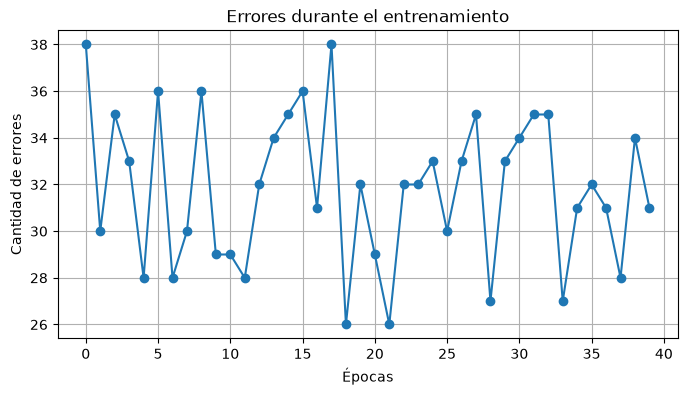

In [ ]:
# Creación del perceptrón
class PerceptronEstudiantes:
    def __init__(self, learning_rate=0.05, n_epochs=50):
        self.lr = learning_rate
        self.n_epochs = n_epochs
        self.weights = None
        self.bias = 0.0
        self.error_history = []

    # Función de activación
    def activacion(self, z):
        return np.where(z >= 0, 1, 0)

    # Entrenamiento del modelo
    def fit(self, X, y):
        self.weights = np.zeros(X.shape[1])
        self.bias = 0.0

        for _ in range(self.n_epochs):
            errors = 0

            for xi, target in zip(X, y):
                prediccion = self.activacion(np.dot(xi, self.weights) + self.bias)
                actualizacion = self.lr * (target - prediccion)

                self.weights += actualizacion * xi
                self.bias += actualizacion
                errors += int(actualizacion != 0)

            self.error_history.append(errors)

    # Predicción de nuevos datos
    def predict(self, X):
        return self.activacion(np.dot(X, self.weights) + self.bias)


# Entrenamiento del perceptrón
mi_perceptron = PerceptronEstudiantes(learning_rate=0.05, n_epochs=40)
mi_perceptron.fit(X_train_scaled, y_train)

print("Pesos:", mi_perceptron.weights)
print("Sesgo:", mi_perceptron.bias)

# Gráfica del aprendizaje
plt.figure(figsize=(8, 4))
plt.plot(mi_perceptron.error_history, marker='o')
plt.title("Errores durante el entrenamiento")
plt.xlabel("Épocas")
plt.ylabel("Cantidad de errores")
plt.grid(True)
plt.show()

## Explicación de la Seccion 4
* Implementamos el perceptrón utilizando Python y NumPy, sin depender de librerías externas para el entrenamiento. En cada época, el modelo revisa sus predicciones y ajusta los pesos y el sesgo cuando comete errores. La gráfica muestra cómo evoluciona la cantidad de errores durante el aprendizaje

In [5]:
# EVALUACION Y METRICAS

from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score

# Probamos con el 20% de los datos que el modelo jamas habia visto
y_pred = mi_perceptron.predict(X_test_scaled)

exactitud = accuracy_score(y_test, y_pred)
presicion = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
matriz = confusion_matrix(y_test, y_pred)

print(f"Exactitud:  {exactitud * 100:.2f}%")
print(f"Precision: {presicion * 100:.2f}%")
print(f"Recall: {recall * 100:.2f}%")
print("\nMatriz de Confusion:")
print(matriz)

Exactitud:  90.00%
Precision: 90.48%
Recall: 82.61%

Matriz de Confusion:
[[35  2]
 [ 4 19]]


## Explicacion de la Seccion 5
*Evaluamos el rendimiento del modelo utilizando tres métricas: la exactitud, que indica el porcentaje de vías clasificadas correctamente; la precisión, que muestra cuántas de las vías que el modelo identificó para reparar realmente necesitaban intervención; y el recall, que mide cuántas de las vías que necesitaban reparación logró detectar.

### ¿Que significan los pesos?
* Indican la importancia de cada variable. En nuestro caso, los huecos y la accidentalidad tienen mayor influencia en la decisión de reparar una vía.

### ¿Cual es el error mas grave?
* El falso negativo: cuando el modelo dice que una vía no necesita reparación, aunque realmente sí la necesita.

### Limitaciones del Perceptron
* Modelo lineal: Tiene dificultades para identificar relaciones complejas.
* Datos limitados: Está entrenado con datos de Zipaquirá, por lo que necesitaría nuevos datos para funcionar en otros municipios.

In [6]:
# Prueba con una vía nueva
nueva_via = np.array([[2500, 35, 20, 10]])

# Normalizamos con los valores del entrenamiento
nueva_via_scaled = (nueva_via - media) / desviacion

# Realizamos la predicción
resultado = mi_perceptron.predict(nueva_via_scaled)

print("Resultado:", "Necesita reparación" if resultado[0] == 1 else "No necesita reparación")

Resultado: Necesita reparación


### Prueba del percetron 
Anteriormente probamos el perceptrón con datos aleatorios. En este caso, le pasamos un array con el tráfico, la cantidad de huecos, la antigüedad y la accidentalidad de una vía. Luego normalizamos los datos y los enviamos al modelo, que finalmente nos indica si la vía necesita reparación o no.

## 7. Conclusiones

Demostramos que organizar las obras publicas no tiene por que basarse en temas politicos o en a quien le vaya mejor con el alcalde, sino en datos casi 100% exactos y claros como cuantos huecos hay y cuantos carros pasan.

Las comunidades o diferentes sectores pueden armar una tabla basica de Excel en sus barrios con estas variables para ir registrando el estado de sus calles. Asi, cuando vayan a reclamar a la Secretaria de Infraestructura de Ubate, llevan argumentos tecnicos reales y datos falsos o volando.